<a href="https://colab.research.google.com/github/ntienvo/ML-lab/blob/main/Lab01_Tabular_Student_Updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 — Tabular Data Machine Learning Pipeline
**Dataset:** Breast Cancer Wisconsin (Diagnostic)  
**Task:** Binary classification

## Overview
Build an end-to-end machine learning pipeline for tabular data: inspect the dataset, explore feature distributions, split the data correctly, train baseline and classification models, evaluate errors, and investigate data leakage.

## Learning objectives
By the end of this lab, you should be able to:
- Inspect a tabular dataset with Pandas.
- Explore feature distributions and differences in feature scales.
- Create a reproducible, stratified train/test split.
- Use `Pipeline` to combine preprocessing and model training.
- Compare a majority-class baseline, KNN, and Logistic Regression.
- Evaluate classification with accuracy, precision, recall, F1-score, and a confusion matrix.
- Use cross-validation on training data only.
- Explain why fitting preprocessing on the full dataset can cause leakage.

## Important rules
- Use `random_state=42` for reproducibility.
- The dataset encodes **0 = malignant** and **1 = benign**. Confirm this using the dataset metadata.
- In this lab, precision, recall, and F1 are calculated for the malignant class (`pos_label=0`).
- Do not use the test set to select models or hyperparameters.
- Complete the TODOs and answer the discussion questions.

## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split, cross_validate, StratifiedKFold, GridSearchCV
)
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    make_scorer
)

RANDOM_STATE = 42

!git config --global user.name "ntienvo"
!git config --global user.email "08.ngoctien@gmail.com"

## Part 1 — Load and inspect

### Task 1.1 — Load the dataset
Load the dataset with `load_breast_cancer(as_frame=True)`. Assign the feature matrix to `X` and target labels to `y`.

In [ ]:
# TODO: Load the dataset.
data = load_breast_cancer(as_frame=True)

# TODO: Assign the feature matrix and target labels.
X, y = data.data, data.target

# YOUR CODE HERE

In [ ]:
# Run this cell after completing Task 1.1.
print("X shape:", X.shape, "y shape:", y.shape)
print("Target names:", data.target_names)
display(X.dtypes.value_counts())

X shape: (569, 30) y shape: (569,)
Target names: ['malignant' 'benign']


,count
float64,30


### Task 1.2 — Inspect the dataset

In [ ]:
from pandas.core.dtypes.missing import isnull
# TODO: Create a DataFrame containing all features and a "target" column.
df = X.copy()
df["target"] = y
display(df.head())
# TODO: Display the first rows.
display(df.head(1))
# TODO: Display descriptive statistics for all features.
display(df.describe().T)
# TODO: Display missing-value counts.
display(df.isna().sum().head(10))
# YOUR CODE HERE

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


In [ ]:
# TODO: Count the target classes and plot a bar chart.
# Keep the index labels clear: malignant (0) and benign (1).

### Discussion questions
1. How many samples and features are in the dataset?
2. Are there missing values?
3. Are the two target classes equally represented?
4. Why can class imbalance make accuracy alone misleading?

## Part 2 — Explore features

### Task 2.1 — Plot feature distributions
Use the following three features:
- `mean radius`
- `mean texture`
- `mean area`

Create three histograms in one figure, label the axes, and give each histogram a title.

,count
malignant (0),357
benign (1),212


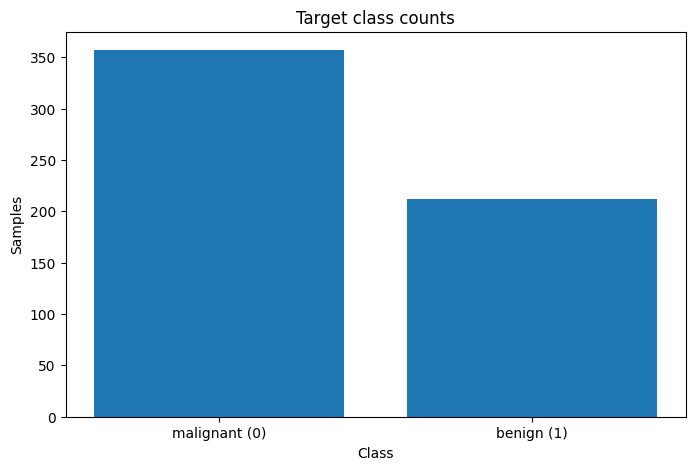

In [ ]:
features = ["mean radius", "mean texture", "mean area"]
counts = y.value_counts()
counts.index = ["malignant (0)", "benign (1)"]
display(counts.to_frame(name = "count"))

plt.figure(figsize = (8, 5))
plt.bar(counts.index, counts.values)
plt.title("Target class counts")
plt.xlabel("Class")
plt.ylabel("Samples")
plt.show()
# TODO: Create a figure with three subplots.
# TODO: Plot a histogram for each feature.
# TODO: Add titles and axis labels, then show the figure.

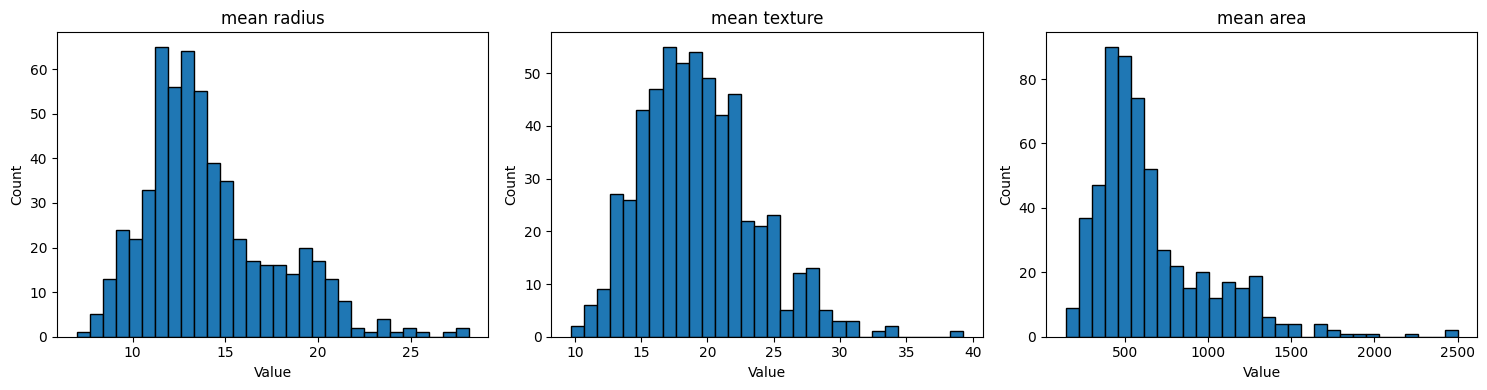

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981,11.70,13.37,15.78,28.11
mean texture,569.0,19.289649,4.301036,9.710,16.17,18.84,21.80,39.28
mean area,569.0,654.889104,351.914129,143.500,420.30,551.10,782.70,2501.00


In [ ]:
# TODO: Display descriptive statistics for the three selected features.
features = ["mean radius", "mean texture", "mean area"]
axes = df[features].hist(figsize = (15,4), bins = 30, layout=(1,3), grid=False, edgecolor = "black")
for ax in axes.flatten():
  ax.set(xlabel = "Value", ylabel = "Count")
plt.tight_layout()
plt.show()
display(df[features].describe().T)

### Discussion questions
1. Do the three features have similar numerical ranges?
2. Why can large-range features dominate distance calculations in KNN?
3. Why is standardization useful for KNN and many linear optimization methods?
4. Do all machine learning models require standardization? Explain briefly.

## Part 3 — Split data

Reserve 20% of the dataset for the test set. Use a fixed random seed and stratify by the target so the class proportions remain similar.

In [ ]:
# TODO: Split X and y into training and test sets.
# Required arguments: test_size=0.20, random_state=RANDOM_STATE, stratify=y
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "Test:", X_test.shape)

# YOUR CODE HERE

Train: (455, 30) Test: (114, 30)
Train proportions: 


,proportion
target,
0,0.373626
1,0.626374


Test proportions: 


,proportion
target,
0,0.368421
1,0.631579


In [ ]:
# TODO: Print training and test shapes.
# TODO: Display class proportions in the training and test sets.
print("Train proportions: ")
display(y_train.value_counts(normalize = True).sort_index().rename("proportion"))

print("Test proportions: ")
display(y_test.value_counts(normalize = True).sort_index().rename("proportion"))

Train proportions: 


,proportion
target,
0,0.373626
1,0.626374


Test proportions: 


,proportion
target,
0,0.368421
1,0.631579


### Discussion questions
1. What does `stratify=y` do?
2. Why should the test set be reserved for final evaluation?
3. What can go wrong if you repeatedly change the model after checking test performance?

## Part 4 — Baseline

A baseline provides a reference point for judging whether a more complex model is useful.

### Task 4.1 — Implement an evaluation function
Implement a function that returns:
- accuracy
- malignant precision
- malignant recall
- malignant F1-score

Use `pos_label=0` and `zero_division=0` for precision, recall, and F1.

In [ ]:
def evaluate_binary_classifier(y_true, y_pred):
  return {
      "accuracy": accuracy_score(y_true, y_pred),
      "malignant_precision": precision_score(y_true, y_pred, pos_label = 0, zero_division = 0),
      "malignant_recall": recall_score(y_true, y_pred, pos_label= 0, zero_division = 0),
      "malignant_f1": f1_score(y_true, y_pred, pos_label=0, zero_division=0)
  }
    # TODO: Return a dictionary with accuracy, malignant_precision,
    # malignant_recall, and malignant_f1

### Task 4.2 — Train the baseline

In [ ]:
# TODO: Create DummyClassifier(strategy="most_frequent").
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

# TODO: Fit the baseline on X_train and y_train.
# TODO: Predict labels for X_test.
baseline_pred = baseline.predict(X_test)

# TODO: Display the evaluation metrics as a one-row DataFrame.
display(pd.DataFrame(
    [evaluate_binary_classifier(y_test, baseline_pred)], index = [DummyClassifier]).round(3)
)

,accuracy,malignant_precision,malignant_recall,malignant_f1
<class 'sklearn.dummy.DummyClassifier'>,0.632,0.0,0.0,0.0


### Discussion questions
1. Why is a majority-class classifier a useful baseline?
2. Can a baseline have reasonable accuracy but poor malignant recall?
3. Why might malignant recall matter in a screening scenario? This is an educational example, not a clinical model.

## Part 5 — Model pipelines
Build each pipeline with median imputation, standardization, and the classifier. The dataset currently has no missing values, but the imputer demonstrates a reusable workflow.

### Task 5.1 — KNN pipeline
Use `KNeighborsClassifier(n_neighbors=5)`.

In [ ]:
# TODO: Build a Pipeline with these steps, in order:
# 1. SimpleImputer(strategy="median")
# 2. StandardScaler()
# 3. KNeighborsClassifier(n_neighbors=5)
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])
knn_pipeline.fit(X_train, y_train)
knn_pred = knn_pipeline.predict(X_test)

# TODO: Fit the pipeline on X_train and y_train.
# TODO: Predict X_test and store the predictions in knn_pred.

### Task 5.2 — Logistic Regression pipeline

In [ ]:
# TODO: Build a Pipeline with these steps, in order:
# 1. SimpleImputer(strategy="median")
# 2. StandardScaler()
# 3. LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logreg_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42)),
])
logreg_pipeline.fit(X_train, y_train)
logreg_pred = logreg_pipeline.predict(X_test)
# TODO: Fit the pipeline and predict labels for X_test.

### Task 5.3 — Compare the models

In [ ]:
# TODO: Use evaluate_binary_classifier to compare:
# DummyClassifier, KNN (k=5), and Logistic Regression.
results = pd.DataFrame([
    evaluate_binary_classifier(y_test,baseline_pred),
    evaluate_binary_classifier(y_test, knn_pred),
    evaluate_binary_classifier(y_test, logreg_pred),
], index=["DummyClassifier", "KNN (k=5)", "Logistic Regression"])

# Display a DataFrame indexed by model name, rounded to 3 decimal places.
display(results.sort_values("malignant_f1", ascending = False).round(3))

,accuracy,malignant_precision,malignant_recall,malignant_f1
Logistic Regression,0.982,0.976,0.976,0.976
KNN (k=5),0.956,0.951,0.929,0.940
DummyClassifier,0.632,0.000,0.000,0.000


### Discussion questions
1. Which model has the best malignant F1-score?
2. Does the model with the best F1-score also have the best malignant recall?
3. Why is it useful to report multiple metrics?
4. Why are imputation and scaling inside the pipeline rather than fitted separately before splitting?

## Part 6 — Confusion matrix and errors

For consistency with the instructor solution, use the **Logistic Regression** predictions in this section.

### Task 6.1 — Evaluate and visualize errors
1. Print a classification report with labels ordered `[0, 1]` and target names `["malignant", "benign"]`.
2. Plot a confusion matrix with the same label order.
3. Find the misclassified test samples and display their features, true labels, and predicted labels.

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



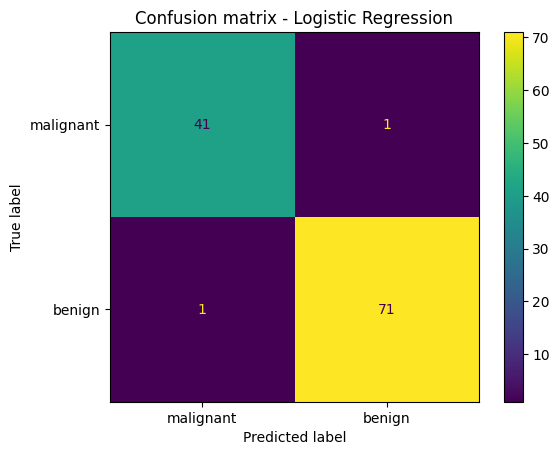

In [ ]:
# TODO: Print classification_report for logreg_pred.
# Use labels=[0, 1], target_names=["malignant", "benign"], zero_division=0.
# TODO: Compute and plot the confusion matrix.
# Use display labels ["malignant", "benign"].
print(classification_report(
    y_test, logreg_pred,
    labels = [0,1],
    target_names = ["malignant","benign"],
    zero_division = 0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, logreg_pred,
    labels=[0, 1],
    display_labels = ["malignant", "benign"],
    cmap="viridis"
)

plt.title("Confusion matrix - Logistic Regression")
plt.show()

In [ ]:
# TODO: Find test positions where logreg_pred differs from y_test.
# TODO: Select those rows from X_test.
# TODO: Add true_label and predicted_label columns with readable class names.
# TODO: Display up to five errors.

errors = np.where(logreg_pred != np.array(y_test))[0]

wrong = X_test.iloc[errors].copy()
wrong["true_label"] = y_test.iloc[errors].map({0: "malignant", 1: "benign"}).values
wrong["predicted_label"] = pd.Series(logreg_pred[errors]).map({0: "malignant", 1: "benign"}).values
display(wrong.head(5))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,true_label,predicted_label
541,14.47,24.99,95.81,656.4,0.08837,0.123,0.10090,0.03890,0.1872,0.06341,...,113.5,808.9,0.1340,0.4202,0.4040,0.1205,0.3187,0.1023,benign,malignant
73,13.80,15.79,90.43,584.1,0.10070,0.128,0.07789,0.05069,0.1662,0.06566,...,110.3,812.4,0.1411,0.3542,0.2779,0.1383,0.2589,0.1030,malignant,benign


### Discussion questions
1. How many malignant samples were predicted as benign?
2. How many benign samples were predicted as malignant?
3. Which error type is more concerning for this example, and why?
4. What patterns, if any, do you notice in the misclassified samples? Avoid claiming that a pattern proves causation or clinical validity.

## Part 7 — Cross-validation on training data only

Use five-fold stratified cross-validation to compare KNN and Logistic Regression. Run cross-validation on `X_train, y_train` only. The test set must remain outside model selection.

### Task 7.1
Create scorers for malignant F1 and malignant recall. Use:
`StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)`.

Report the mean and standard deviation for accuracy, malignant F1, and malignant recall.

In [ ]:
malignant_f1 = make_scorer(f1_score, pos_label=0, zero_division=0)
malignant_recall = make_scorer(recall_score, pos_label=0, zero_division=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "malignant_f1": malignant_f1,
    "malignant_recall": malignant_recall
}

# TODO: Run cross_validate for knn_pipeline and logreg_pipeline
# on X_train and y_train. Build a results DataFrame with each metric's
# mean and standard deviation across folds.

### Discussion questions
1. Why is cross-validation performed on the training set rather than the test set?
2. What does a large standard deviation across folds suggest?
3. Does a difference between cross-validation and test results automatically mean the experiment is wrong?

## Part 8 — Preprocessing leakage

A common mistake is fitting a scaler on the full dataset before splitting. The scaler then uses information about the test feature distribution.

### Task 8.1 — Compare the learned means
1. Fit one `StandardScaler` on all of `X` (incorrect for evaluation).
2. Fit another `StandardScaler` on `X_train` only (correct).
3. Compare their learned means and calculate the absolute differences.
4. Display the ten features with the largest differences.

In [ ]:
# TODO: Fit scaler_all on X and scaler_train on X_train.
scaler_all = None
scaler_train = None

# TODO: Build a DataFrame with columns:
# "fit_on_all_data", "fit_on_training_only", "absolute_difference"
# Use X.columns as the index.
# Display the 10 rows with the largest absolute differences.
# Print the maximum absolute difference in learned means.

### Discussion questions
1. Why is fitting preprocessing on the full dataset considered leakage?
2. Why might the numerical difference be small even though the procedure is still incorrect?
3. How does using a Pipeline help prevent this problem during cross-validation?

## Optional challenge — GridSearchCV

If time permits, tune KNN's `n_neighbors` using cross-validation on the training set only. Use the existing `malignant_f1` scorer and `cv` object. After selecting the best hyperparameter, evaluate the selected estimator on the test set once.

In [ ]:
param_grid = {"model__n_neighbors": [3, 5, 7, 11, 15]}

# TODO: Create search_pipe using:
# SimpleImputer(strategy="median") -> StandardScaler() -> KNeighborsClassifier()
search_pipe = None

# TODO: Create GridSearchCV with:
# estimator=search_pipe, param_grid=param_grid, scoring=malignant_f1,
# cv=cv, n_jobs=-1.
search = None

# TODO: Fit on X_train, y_train.
# TODO: Print best_params_ and best_score_.
# TODO: Predict X_test and display metrics using evaluate_binary_classifier.